## PROGRES 1

judul : Perbandingan Metode SARIMA dan Regresi Linear dalam Peramalan Jumlah Kejadian SAR di Kantor Pencarian dan Pertolongan Surabaya.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True

print("Library berhasil diimpor.")


Library berhasil diimpor.


In [ ]:

from google.colab import files

uploaded = files.upload()

nama_file = next(iter(uploaded))

df = pd.read_excel(nama_file, sheet_name='DATA_GABUNGAN')

print("Data berhasil dibaca.")
print("Ukuran data:", df.shape)

display(df.head())


Saving DATA_SAR_GABUNGAN_2023_2026.xlsx to DATA_SAR_GABUNGAN_2023_2026 (1).xlsx
Data berhasil dibaca.
Ukuran data: (616, 73)


,TAHUN,BULAN,SHEET_ASAL,FILE_ASAL,KOLOM_01,KOLOM_02,KOLOM_03,KOLOM_04,KOLOM_05,KOLOM_06,...,KOLOM_60,KOLOM_61,KOLOM_62,KOLOM_63,KOLOM_64,KOLOM_65,KOLOM_66,KOLOM_67,KOLOM_68,KOLOM_69
0,2023,JANUARI,JANUARI 2023,DATA KEJADIAN 2023 (1).xlsx,1.0,MAN OVER BOAT,"1 (Satu) Org. Pemancing, Korban An. Iwan Wahyu...","Di Perairan Selatan Karang Jamuang, pada koord...",1231 1400 G,0101 0830 G,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023,JANUARI,JANUARI 2023,DATA KEJADIAN 2023 (1).xlsx,2.0,MAN OVER BOAT,"1 (Satu) Org. ABK KMN RADEN JOYO 3, Korban An....","Di Perairan Keramaian Sumenep, pada koordinat ...",0104 1600 G,0105 2245 G,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2023,JANUARI,JANUARI 2023,DATA KEJADIAN 2023 (1).xlsx,3.0,KAPAL TERBAKAR,"KM FORTUNER mengalami terbakar, dgn. Jumlah PO...",Di depan Pelabuhan Petro Gresik pada titik koo...,\n0112 1635 G\n,0112 1815 G,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2023,JANUARI,JANUARI 2023,DATA KEJADIAN 2023 (1).xlsx,4.0,HILANG KONTAK,Kapal Kayu Dgn. Warna Biru Dongker Kma Dgn. 5 ...,"Di Perairan Kma Dgn. Rute Bawean Bangkalan, Ma...",0115 1600 G,0118 1800 G,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2023,JANUARI,JANUARI 2023,DATA KEJADIAN 2023 (1).xlsx,5.0,MAN OVER BOAT,"1 (Satu) Org. Korban An. Hafid, Jenis Kelamin ...","Di KAB. Ketapang, Pada Koordinat Duga Lokasi K...",0128 1700 G,0129 0830 G,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

data = df.copy()

data['TAHUN'] = pd.to_numeric(
    data['TAHUN'], errors='coerce'
)

data['BULAN'] = (
    data['BULAN']
    .astype(str)
    .str.strip()
    .str.upper()
)

peta_bulan = {
    'JANUARI': 1,
    'FEBRUARI': 2,
    'MARET': 3,
    'APRIL': 4,
    'MEI': 5,
    'JUNI': 6,
    'JULI': 7,
    'AGUSTUS': 8,
    'SEPTEMBER': 9,
    'OKTOBER': 10,
    'NOVEMBER': 11,
    'DESEMBER': 12
}

data['NOMOR_BULAN'] = data['BULAN'].map(peta_bulan)

# Periksa data tahun atau bulan yang tidak terbaca
print("Tahun kosong:", data['TAHUN'].isna().sum())
print("Bulan tidak dikenali:", data['NOMOR_BULAN'].isna().sum())

# Hanya menghapus baris yang tidak memiliki periode
data = data.dropna(
    subset=['TAHUN', 'NOMOR_BULAN']
).copy()

data['TAHUN'] = data['TAHUN'].astype(int)
data['NOMOR_BULAN'] = data['NOMOR_BULAN'].astype(int)

# Mengeluarkan Oktober 2026 dan bulan setelahnya
data = data[
    (data['TAHUN'] < 2026) |
    (
        (data['TAHUN'] == 2026) &
        (data['NOMOR_BULAN'] <= 9)
    )
].copy()

print("\nJumlah data setelah pembatasan periode:", len(data))
print("Periode penelitian: Januari 2023 - September 2026")


Tahun kosong: 0
Bulan tidak dikenali: 0

Jumlah data setelah pembatasan periode: 604
Periode penelitian: Januari 2023 - September 2026


In [ ]:
data_bulanan = (
    data.groupby(['TAHUN', 'NOMOR_BULAN'])
    .size()
    .reset_index(name='JUMLAH_KEJADIAN')
)

data_bulanan['TANGGAL'] = pd.to_datetime({
    'year': data_bulanan['TAHUN'],
    'month': data_bulanan['NOMOR_BULAN'],
    'day': 1
})

data_bulanan = data_bulanan.sort_values('TANGGAL')

# Membuat deret waktu bulanan
time_series = (
    data_bulanan
    .set_index('TANGGAL')['JUMLAH_KEJADIAN']
    .asfreq('MS')
)

print("=== DATA KEJADIAN SAR BULANAN ===")
display(data_bulanan)

print("Jumlah periode:", len(time_series))
print("Jumlah NaN pada deret waktu:", time_series.isna().sum())

if time_series.isna().any():
    print("PERINGATAN: Ada bulan yang belum memiliki data.")
else:
    print("Semua periode bulanan tersedia.")


=== DATA KEJADIAN SAR BULANAN ===


,TAHUN,NOMOR_BULAN,JUMLAH_KEJADIAN,TANGGAL
0,2023,1,16,2023-01-01
1,2023,2,20,2023-02-01
2,2023,3,24,2023-03-01
3,2023,4,17,2023-04-01
4,2023,5,16,2023-05-01
5,2023,6,10,2023-06-01
6,2023,7,13,2023-07-01
7,2023,8,9,2023-08-01
8,2023,9,8,2023-09-01
9,2023,10,7,2023-10-01


Jumlah periode: 45
Jumlah NaN pada deret waktu: 0
Semua periode bulanan tersedia.


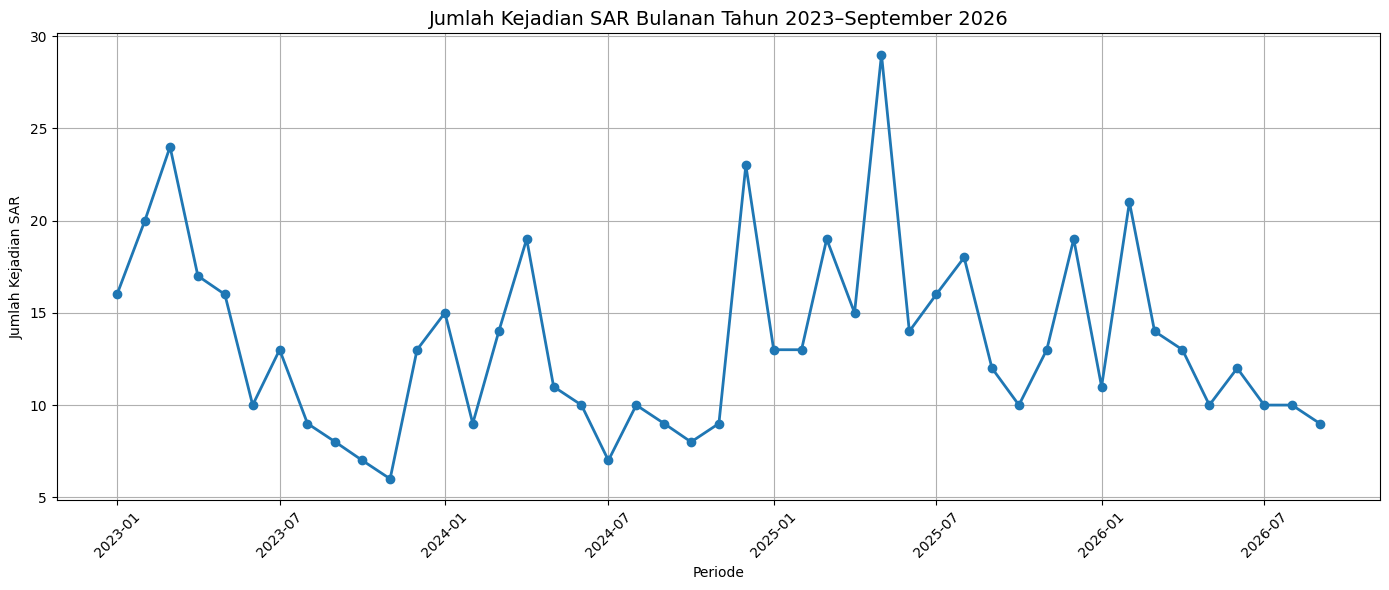

In [ ]:

plt.figure(figsize=(14, 6))

plt.plot(
    time_series.index,
    time_series.values,
    marker='o',
    linewidth=2
)

plt.title(
    'Jumlah Kejadian SAR Bulanan Tahun 2023–September 2026',
    fontsize=14
)

plt.xlabel('Periode')
plt.ylabel('Jumlah Kejadian SAR')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

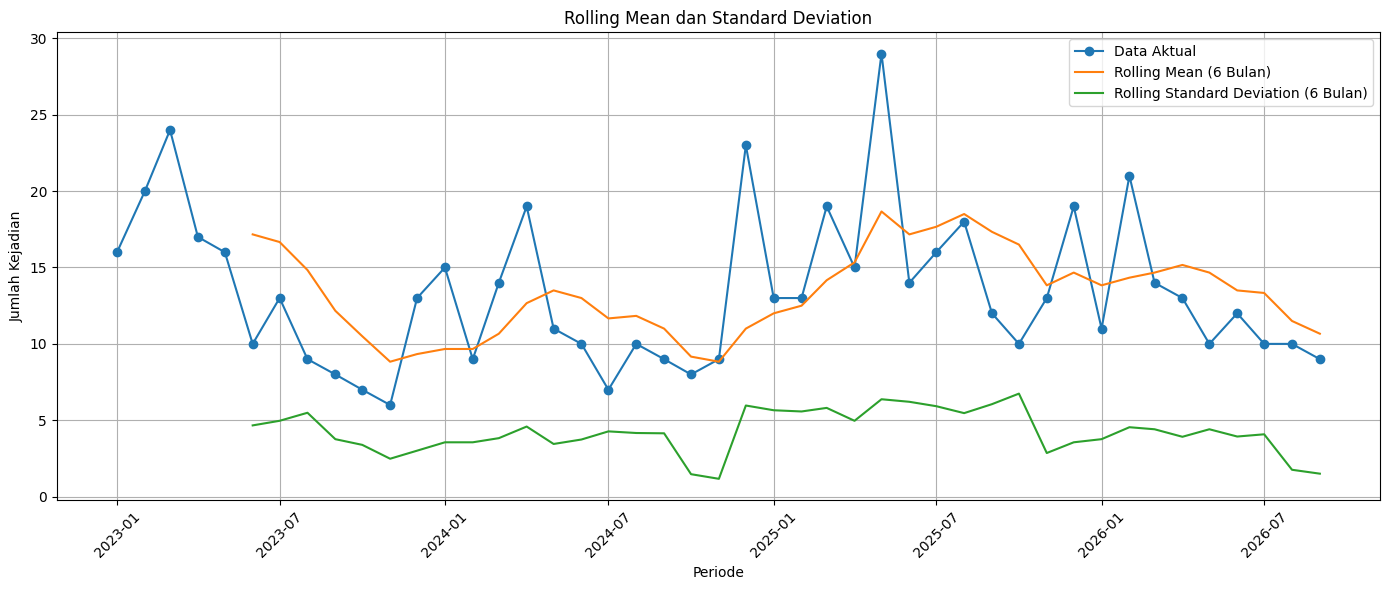

In [ ]:

rolling_mean = time_series.rolling(
    window=6,
    min_periods=6
).mean()

rolling_std = time_series.rolling(
    window=6,
    min_periods=6
).std()

plt.figure(figsize=(14, 6))

plt.plot(
    time_series,
    label='Data Aktual',
    marker='o'
)

plt.plot(
    rolling_mean,
    label='Rolling Mean (6 Bulan)'
)

plt.plot(
    rolling_std,
    label='Rolling Standard Deviation (6 Bulan)'
)

plt.title('Rolling Mean dan Standard Deviation')
plt.xlabel('Periode')
plt.ylabel('Jumlah Kejadian')
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:
hasil_adf = adfuller(
    time_series.dropna(),
    autolag='AIC'
)

print("=== UJI AUGMENTED DICKEY-FULLER ===")
print(f"ADF Statistic : {hasil_adf[0]:.6f}")
print(f"P-Value       : {hasil_adf[1]:.6f}")
print(f"Jumlah Lag    : {hasil_adf[2]}")
print(f"Jumlah Data   : {hasil_adf[3]}")

print("\nNilai Kritis:")
for tingkat, nilai in hasil_adf[4].items():
    print(f"{tingkat}: {nilai:.6f}")

if hasil_adf[1] < 0.05:
    print("\nKESIMPULAN: DATA STASIONER")
else:
    print("\nKESIMPULAN: DATA NONSTASIONER")


=== UJI AUGMENTED DICKEY-FULLER ===
ADF Statistic : -4.599307
P-Value       : 0.000130
Jumlah Lag    : 0
Jumlah Data   : 44

Nilai Kritis:
1%: -3.588573
5%: -2.929886
10%: -2.603185

KESIMPULAN: DATA STASIONER


In [ ]:
hasil_bulanan = data_bulanan[
    ['TANGGAL', 'TAHUN', 'NOMOR_BULAN', 'JUMLAH_KEJADIAN']
].copy()

hasil_bulanan.to_csv(
    'data_sar_bulanan_2023_2026.csv',
    index=False
)

hasil_bulanan.to_excel(
    'data_sar_bulanan_2023_2026.xlsx',
    index=False
)

print("Data bulanan berhasil disimpan.")

files.download('data_sar_bulanan_2023_2026.xlsx')

Data bulanan berhasil disimpan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>